In [9]:
import pandas as pd 
import matplotlib.pylab as plt 
import seaborn as sns 
import openpyxl

In [10]:
df = pd.read_excel('C:\\Users\\olahi\\Desktop\\Linear regression\\Combined cycle power plant\\data\\Folds5x2_pp.xlsx')



In [12]:
df.shape

(9568, 5)

In [13]:
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB


In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
V,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
AP,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
RH,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16
PE,9568.0,454.365009,17.066995,420.26,439.7500,451.550,468.43,495.76


In [17]:
print("Duplicates:", df.duplicated().sum())
print("Missing:", df.isnull().sum().sum())


Duplicates: 41
Missing: 0


In [18]:
df_cleaned = df.drop_duplicates().reset_index(drop=True)

In [19]:
df_cleaned.shape

(9527, 5)

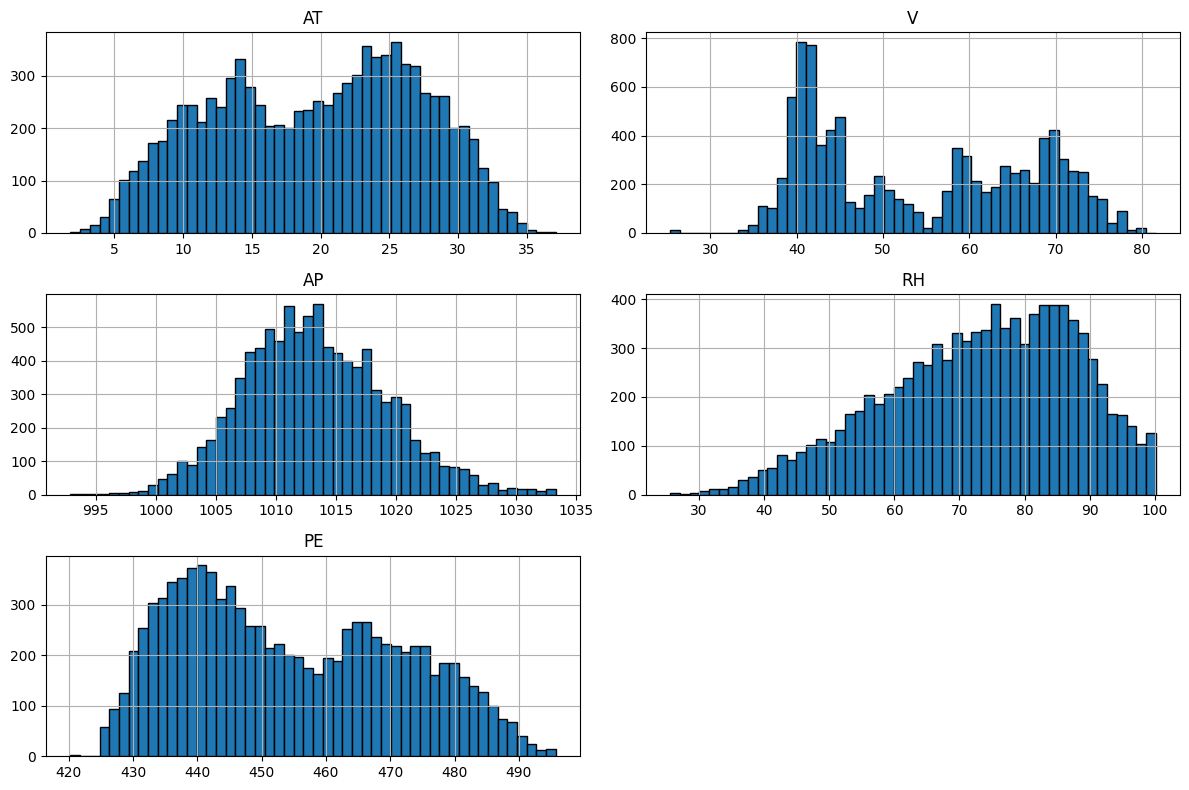

In [20]:
df.hist(bins=50, figsize=(12, 8), edgecolor='black')
plt.tight_layout(); plt.show()

In [ ]:
print(df.skew())          # AP is left-skewed, RH right-skewed
print(df.kurtosis())


AT   -0.136393
V     0.198521
AP    0.265445
RH   -0.431839
PE    0.306509
dtype: float64
AT   -1.037549
V    -1.444337
AP    0.094237
RH   -0.444526
PE   -1.048521
dtype: float64


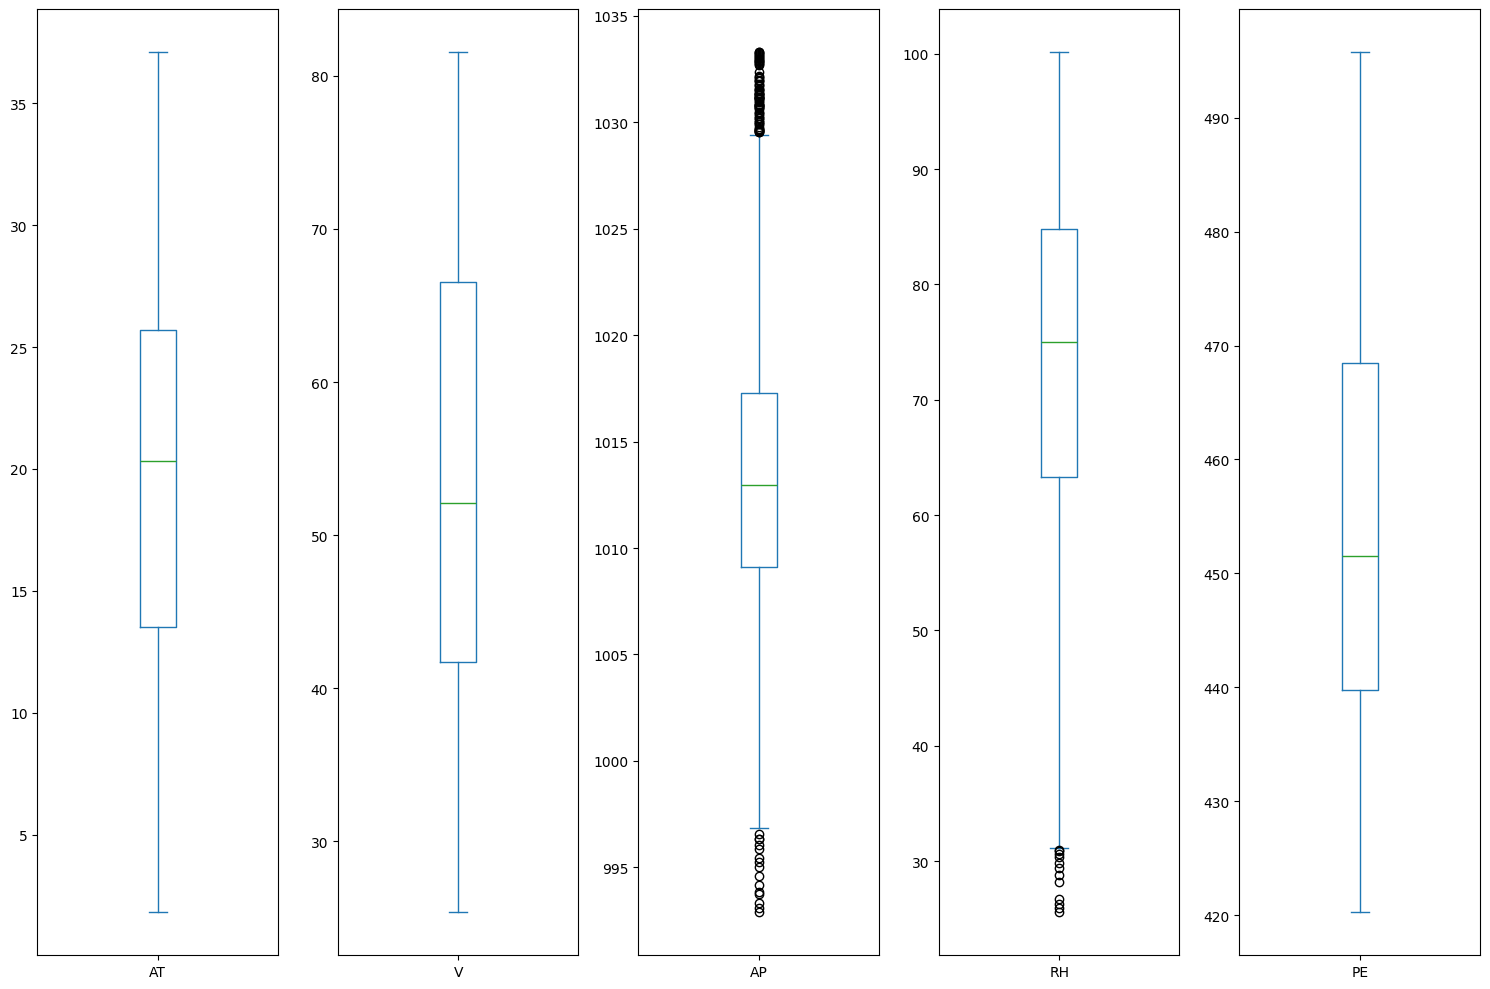

In [26]:
df.plot(kind='box', subplots=True, layout=(1, 5), figsize=(15, 10))
plt.tight_layout(); plt.show()

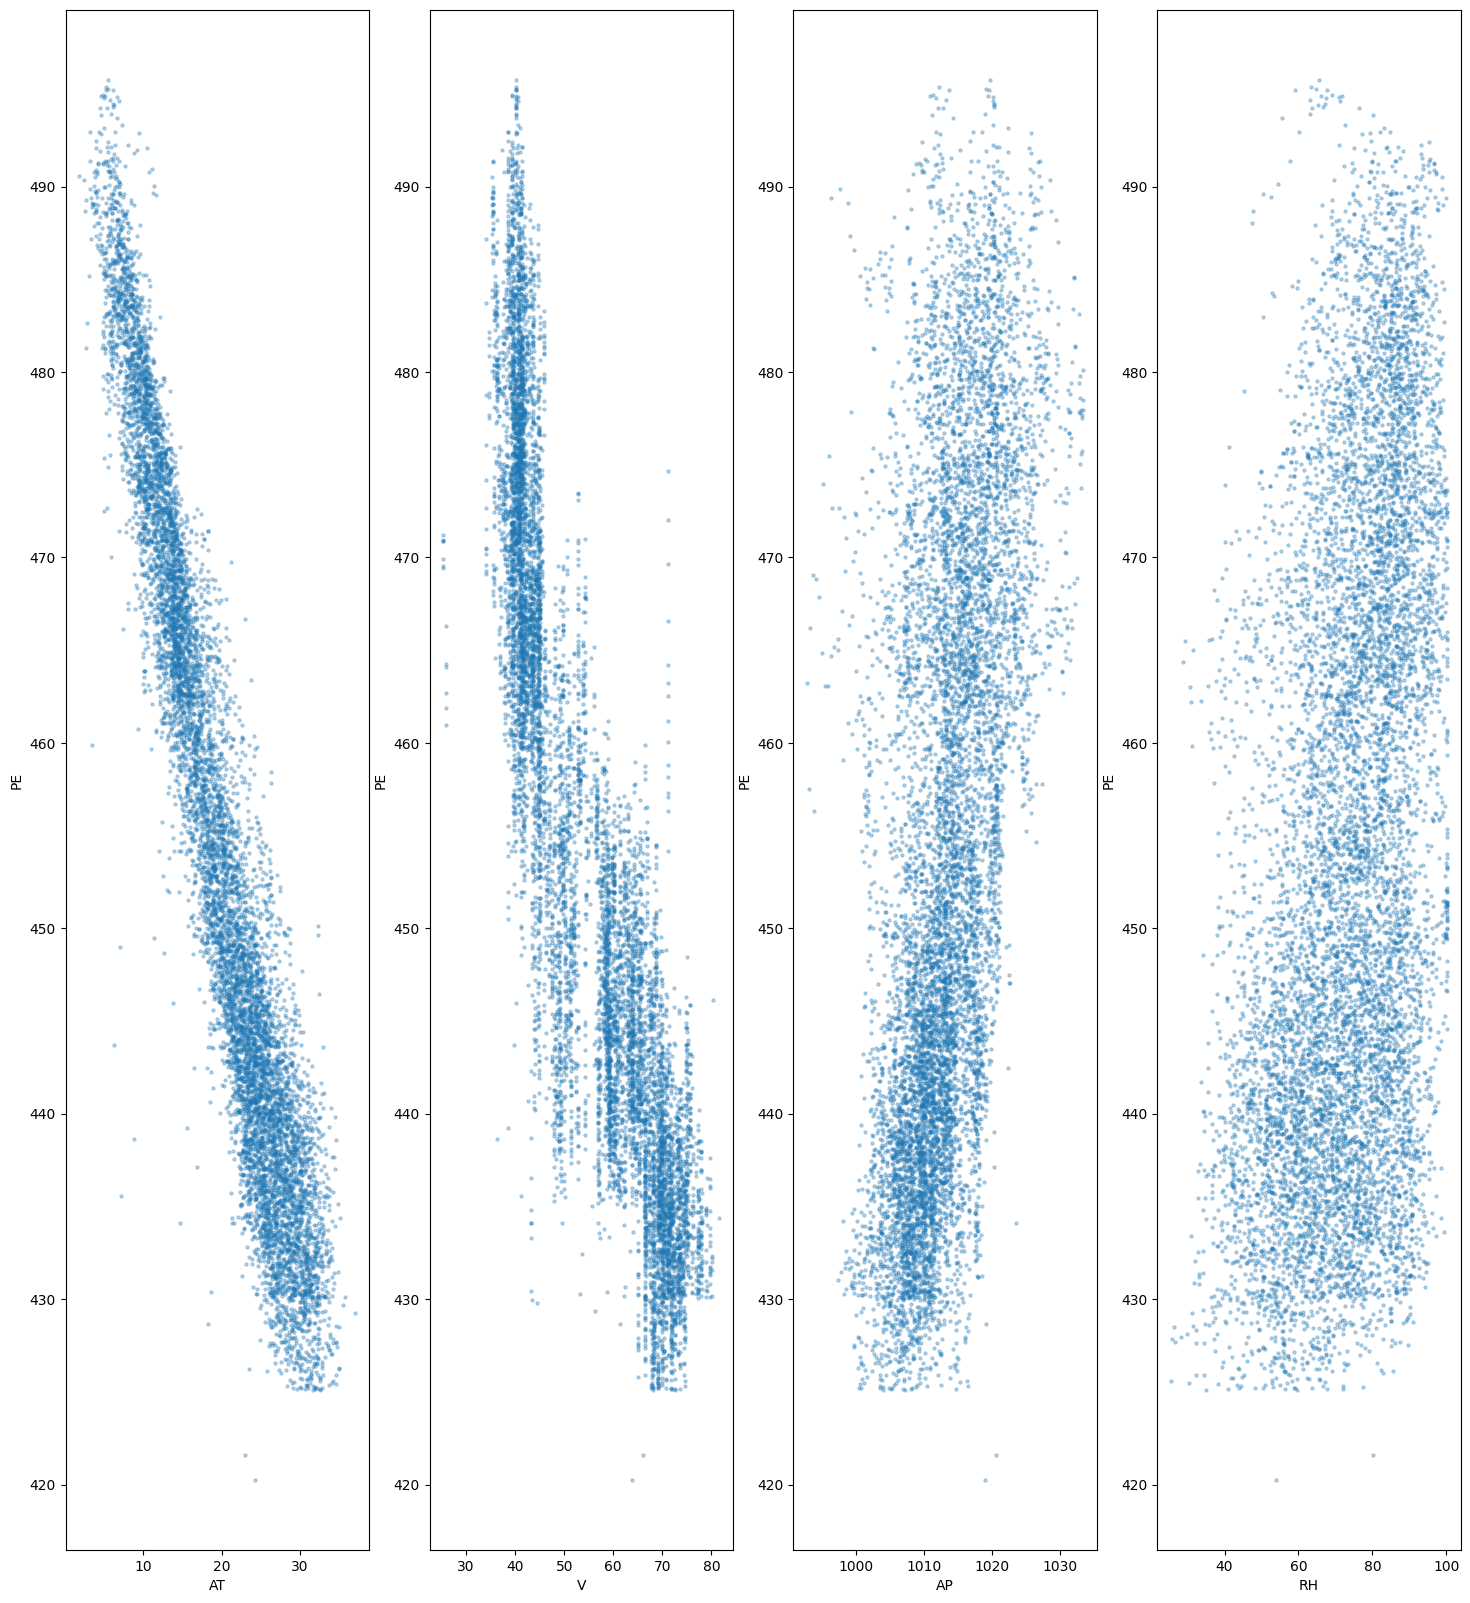

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(18, 20))
for ax, col in zip(axes, ['AT', 'V', 'AP', 'RH']):
    ax.scatter(df[col], df['PE'], s=5, alpha=0.3)
    ax.set_xlabel(col); ax.set_ylabel('PE')
plt.show()


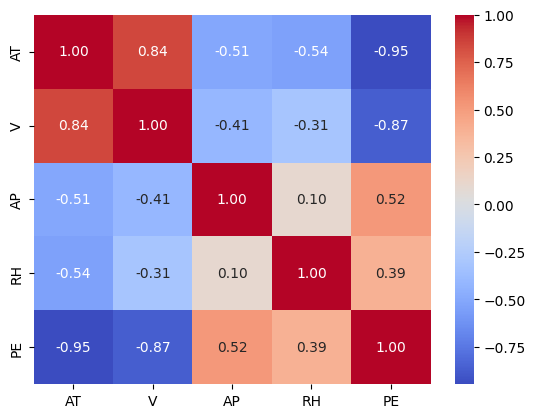

PE    1.000000
AP    0.518429
RH    0.389794
V    -0.869780
AT   -0.948128
Name: PE, dtype: float64


In [29]:
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()
print(corr['PE'].sort_values(ascending=False))


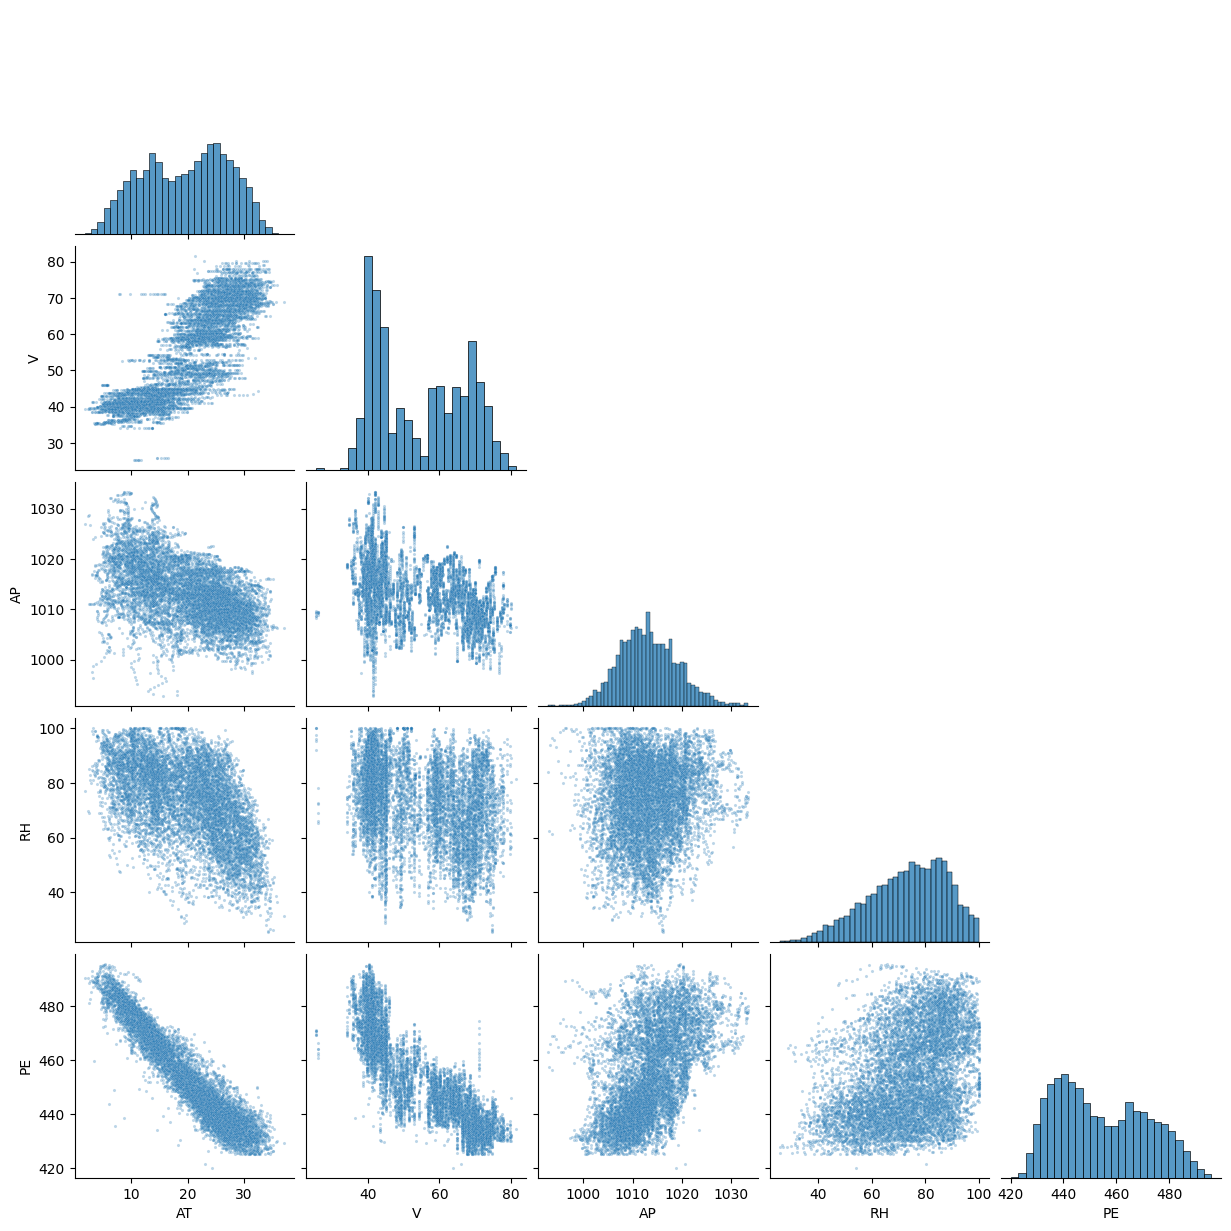

In [30]:
sns.pairplot(df, corner=True, plot_kws={'s': 5, 'alpha': 0.3})
plt.show()

In [32]:
from pathlib import Path

output_path = Path("data") / "cleaned_data.csv"
df_cleaned.to_csv(output_path, index=False)
print(f"Saved to {output_path.resolve()}")

Saved to C:\Users\olahi\Desktop\Linear regression\Combined cycle power plant\data\cleaned_data.csv
